# K-Nearest Neighbors: classifying wheat seeds

**Goal.** Classify a new sample by looking at the samples most similar to it.

**The model.** There is no real training. To predict, the algorithm finds the `k` closest training points and takes a majority vote.
Because it relies on distances, **feature scaling is essential**.

**The dataset.** *Seeds* (UCI): 210 kernels of 3 wheat varieties, with 7 geometric measurements.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "seeds"
archive = download("https://archive.ics.uci.edu/static/public/236/seeds.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Downloading: https://archive.ics.uci.edu/static/public/236/seeds.zip


Saved: data\seeds\dataset.zip (0.0 MB)
Files: ['dataset.zip', 'seeds_dataset.txt']


In [4]:
import pandas as pd

columns = ["area", "perimeter", "compactness", "length", "width", "asymmetry", "groove", "variety"]
# Some rows contain several tabs in a row, so the separator is "any whitespace".
df = pd.read_csv(DATA_DIR / "seeds_dataset.txt", sep=r"\s+", header=None, names=columns)
X, y = df[columns[:-1]], df["variety"]
print("Shape:", X.shape, "| Samples per class:", y.value_counts().to_dict())

Shape: (210, 7) | Samples per class: {1: 70, 2: 70, 3: 70}


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

## 2. Choose k, and see why scaling matters
Small `k` follows noise. Large `k` blurs the classes.

In [6]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

k_values = list(range(1, 41, 2))
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
scaled, unscaled = [], []
for k in k_values:
    scaled.append(cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), X_train, y_train, cv=cv).mean())
    unscaled.append(cross_val_score(KNeighborsClassifier(k), X_train, y_train, cv=cv).mean())

best_k = k_values[int(np.argmax(scaled))]
print("Best k:", best_k, "| CV accuracy:", round(max(scaled), 4))

Best k: 1 | CV accuracy: 0.9335


## 3. Test the final model

In [7]:
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix

model = make_pipeline(StandardScaler(), KNeighborsClassifier(best_k)).fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print("Test accuracy:", round(accuracy, 4))

Test accuracy: 0.9057


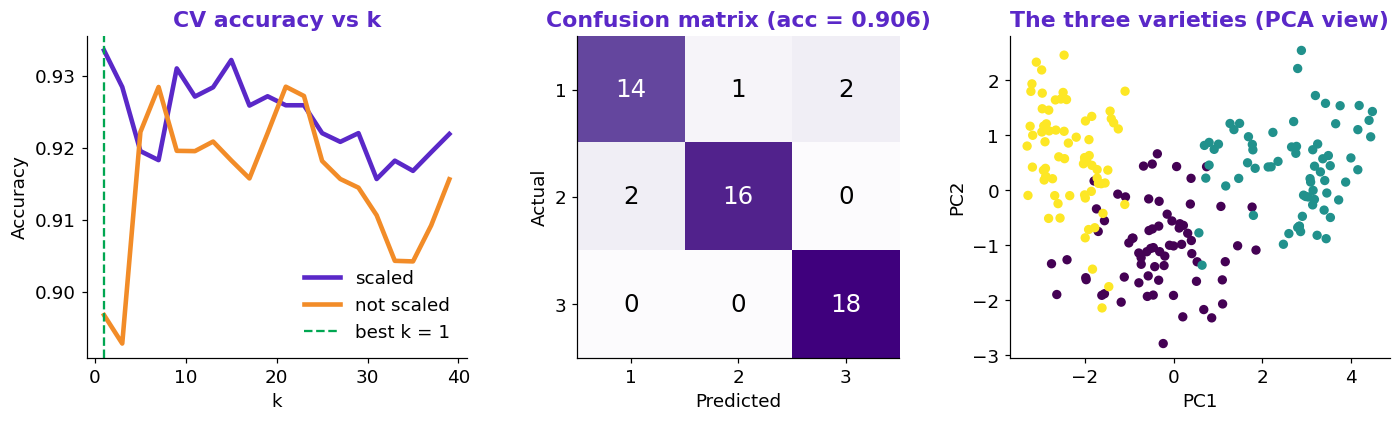

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].plot(k_values, scaled, color=PURPLE, lw=3, label="scaled")
ax[0].plot(k_values, unscaled, color=ORANGE, lw=3, label="not scaled")
ax[0].axvline(best_k, color=GREEN, ls="--", label=f"best k = {best_k}")
ax[0].set(title="CV accuracy vs k", xlabel="k", ylabel="Accuracy")
ax[0].legend()

ax[1].imshow(cm, cmap="Purples")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, v, ha="center", va="center", fontsize=16, color="white" if v > cm.max() / 2 else "black")
ax[1].set(title=f"Confusion matrix (acc = {accuracy:.3f})", xticks=range(3), yticks=range(3),
          xticklabels=[1, 2, 3], yticklabels=[1, 2, 3], xlabel="Predicted", ylabel="Actual")

# Project to 2-D only for drawing. The classifier itself uses all 7 features.
points = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))
ax[2].scatter(points[:, 0], points[:, 1], c=y, cmap="viridis", s=26)
ax[2].set(title="The three varieties (PCA view)", xlabel="PC1", ylabel="PC2")
fig.tight_layout()
plt.show()

In [9]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "06_knn.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "K-Nearest Neighbors",
    "dataset": "Seeds (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"Accuracy": round(accuracy, 4), "Best k": best_k, "CV acc (scaled)": round(max(scaled), 4), "CV acc (not scaled)": round(unscaled[int(np.argmax(scaled))], 4)},
}
(results_dir / "06_knn.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "K-Nearest Neighbors",
  "dataset": "Seeds (UCI)",
  "n_samples": 210,
  "metrics": {
    "Accuracy": 0.9057,
    "Best k": 1,
    "CV acc (scaled)": 0.9335,
    "CV acc (not scaled)": 0.8968
  }
}


## What to remember
- Always scale features before KNN.
- Prediction becomes slow on large datasets, and accuracy suffers in very high dimensions (see notebook 09).